# Convolutional Autoencoder on SVHN Dataset


## 0. Environment Setup


In [1]:
# Install required libraries
!pip install -q tensorflow matplotlib numpy scipy h5py

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import scipy.io
import os
import urllib.request

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print('TensorFlow version:', tf.__version__)
print('GPU Available:', tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset — SVHN (Street View House Numbers)



In [3]:
# Download SVHN dataset (train and test splits)
SVHN_TRAIN_URL = 'http://ufldl.stanford.edu/housenumbers/train_32x32.mat'
SVHN_TEST_URL  = 'http://ufldl.stanford.edu/housenumbers/test_32x32.mat'

def download_file(url, filename):
    if not os.path.exists(filename):
        print(f'Downloading {filename} ...')
        urllib.request.urlretrieve(url, filename)
        print('Done.')
    else:
        print(f'{filename} already exists, skipping download.')

download_file(SVHN_TRAIN_URL, 'train_32x32.mat')
download_file(SVHN_TEST_URL,  'test_32x32.mat')

Done.
Done.


In [4]:
def load_svhn(filepath):
    """
    Load SVHN .mat file.
    Returns images as float32 in range [0, 1], shape (N, 32, 32, 3).
    Labels are returned but will NOT be used in training.
    """
    data = scipy.io.loadmat(filepath)
    # X shape from .mat: (32, 32, 3, N) -> transpose to (N, 32, 32, 3)
    images = data['X'].transpose(3, 0, 1, 2).astype(np.float32) / 255.0
    labels = data['y'].flatten()  # loaded but not used
    return images, labels

X_train, y_train = load_svhn('train_32x32.mat')
X_test,  y_test  = load_svhn('test_32x32.mat')

print('Training set shape  :', X_train.shape)   # (73257, 32, 32, 3)
print('Test set shape      :', X_test.shape)    # (26032, 32, 32, 3)
print('Pixel value range   :', X_train.min(), '-', X_train.max())

Training set shape  : (73257, 32, 32, 3)
Test set shape      : (26032, 32, 32, 3)
Pixel value range   : 0.0 - 1.0


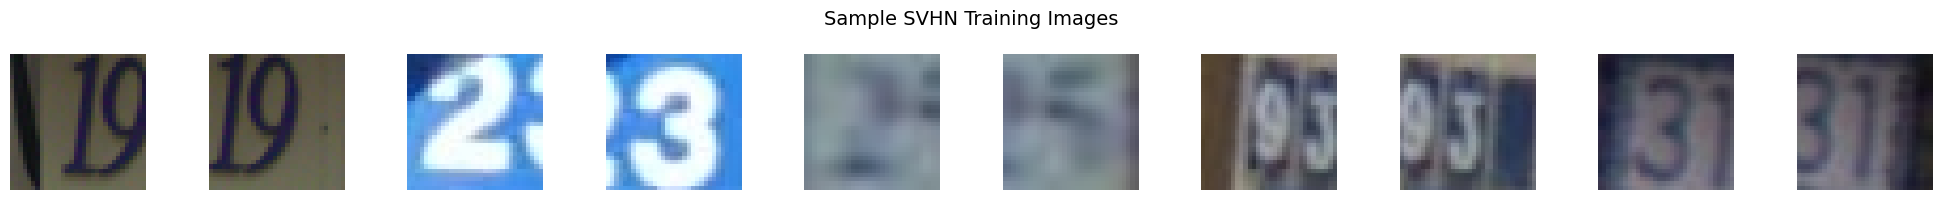

In [5]:
# Quick visual sanity check — display 10 training images
fig, axes = plt.subplots(1, 10, figsize=(20, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i])
    ax.axis('off')
plt.suptitle('Sample SVHN Training Images', fontsize=14)
plt.tight_layout()
plt.show()

## 2. Theoretical Background



## 3. Model Architecture — Convolutional Autoencoder



In [6]:
def build_encoder(latent_dim, input_shape=(32, 32, 3)):
    """
    Convolutional Encoder:
      Input : (32, 32, 3)
      -> Conv2D 32 filters, 3x3, stride 1, same padding  -> (32, 32, 32)
      -> Conv2D 64 filters, 3x3, stride 2, same padding  -> (16, 16, 64)
      -> Conv2D 128 filters, 3x3, stride 2, same padding -> (8, 8, 128)
      -> Flatten -> Dense(latent_dim)  -> latent vector
    """
    inputs = keras.Input(shape=input_shape, name='encoder_input')

    x = layers.Conv2D(32, 3, strides=1, padding='same', activation='relu', name='enc_conv1')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, strides=2, padding='same', activation='relu', name='enc_conv2')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, 3, strides=2, padding='same', activation='relu', name='enc_conv3')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Flatten(name='enc_flatten')(x)
    latent = layers.Dense(latent_dim, activation='relu', name='latent')(x)

    encoder = Model(inputs, latent, name='encoder')
    return encoder


def build_decoder(latent_dim):
    """
    Convolutional Decoder:
      Input : latent vector of size latent_dim
      -> Dense(8*8*128) -> Reshape (8, 8, 128)
      -> Conv2DTranspose 128 filters, stride 1 -> (8, 8, 128)
      -> Conv2DTranspose  64 filters, stride 2 -> (16, 16, 64)
      -> Conv2DTranspose  32 filters, stride 2 -> (32, 32, 32)
      -> Conv2D 3 filters, sigmoid -> (32, 32, 3)  output image
    """
    inputs = keras.Input(shape=(latent_dim,), name='decoder_input')

    x = layers.Dense(8 * 8 * 128, activation='relu', name='dec_dense')(inputs)
    x = layers.Reshape((8, 8, 128), name='dec_reshape')(x)
    x = layers.Conv2DTranspose(128, 3, strides=1, padding='same', activation='relu', name='dec_deconv1')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2DTranspose(64, 3, strides=2, padding='same', activation='relu', name='dec_deconv2')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding='same', activation='relu', name='dec_deconv3')(x)
    x = layers.BatchNormalization()(x)
    outputs = layers.Conv2D(3, 3, strides=1, padding='same', activation='sigmoid', name='dec_output')(x)

    decoder = Model(inputs, outputs, name='decoder')
    return decoder


def build_autoencoder(latent_dim):
    """Combines encoder + decoder into a full autoencoder."""
    encoder = build_encoder(latent_dim)
    decoder = build_decoder(latent_dim)

    inputs = keras.Input(shape=(32, 32, 3), name='autoencoder_input')
    latent  = encoder(inputs)
    outputs = decoder(latent)

    autoencoder = Model(inputs, outputs, name=f'autoencoder_latent{latent_dim}')
    return autoencoder, encoder, decoder


# Build with default latent size = 64
autoencoder_64, encoder_64, decoder_64 = build_autoencoder(latent_dim=64)
autoencoder_64.summary()

Model: "autoencoder_latent64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 64)             │       618,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 32, 32, 3)      │       774,083 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,392,579 (5.31 MB)

 Trainable params: 1,391,683 (5.31 MB)

 Non-trainable params: 896 (3.50 KB)

In [7]:
encoder_64.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv1 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv2 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv3 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_flatten (Flatten)           │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │       524,352 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 618,496 (2.36 MB)

 Trainable params: 618,048 (2.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [8]:
decoder_64.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense (Dense)               │ (None, 8192)           │       532,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_reshape (Reshape)           │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv1 (Conv2DTranspose)   │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv2 (Conv2DTranspose)   │ (None, 16, 16, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv3 (Conv2DTranspose)   │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_output (Conv2D)             │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 774,083 (2.95 MB)

 Trainable params: 773,635 (2.95 MB)

 Non-trainable params: 448 (1.75 KB)

## 4. Training — Latent Size 64


In [9]:
EPOCHS     = 25
BATCH_SIZE = 256
LATENT_DIM = 64

autoencoder_64.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse'
)

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1, min_lr=1e-6)
]

history_64 = autoencoder_64.fit(
    X_train, X_train,          # Input = Target (unsupervised)
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, X_test),
    callbacks=callbacks,
    verbose=1
)

Epoch 1/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 29s 62ms/step - loss: 0.0109 - val_loss: 0.0373 - learning_rate: 0.0010
Epoch 2/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - loss: 0.0051 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 3/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - loss: 0.0037 - val_loss: 0.0053 - learning_rate: 0.0010
Epoch 4/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - loss: 0.0032 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 5/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - loss: 0.0028 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 6/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0025 - val_loss: 0.0028 - learning_rate: 0.0010
Epoch 7/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0023 - val_loss: 0.0025 - learning_rate: 0.0010
Epoch 8/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0022 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 9/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - loss: 0.0021 - val_loss: 0.0028 - learning_rate: 0.

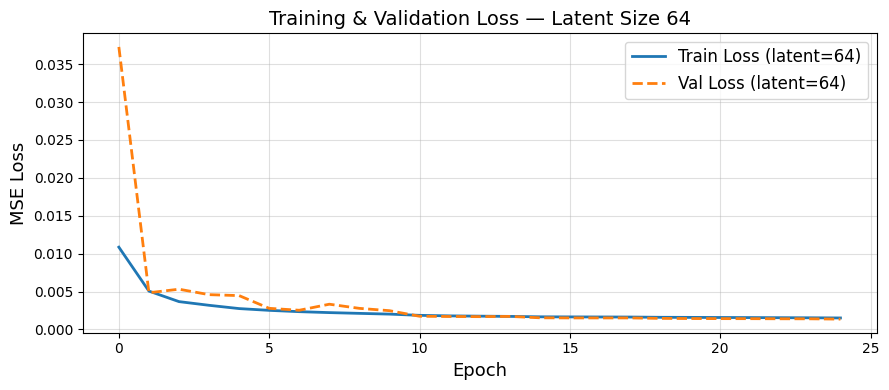

In [10]:
plt.figure(figsize=(9, 4))
plt.plot(history_64.history['loss'],     label='Train Loss (latent=64)', linewidth=2)
plt.plot(history_64.history['val_loss'], label='Val Loss (latent=64)',   linewidth=2, linestyle='--')
plt.xlabel('Epoch', fontsize=13)
plt.ylabel('MSE Loss', fontsize=13)
plt.title('Training & Validation Loss — Latent Size 64', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## 5. Experiment 4.1 — Reconstruction Results (Latent Size 64)



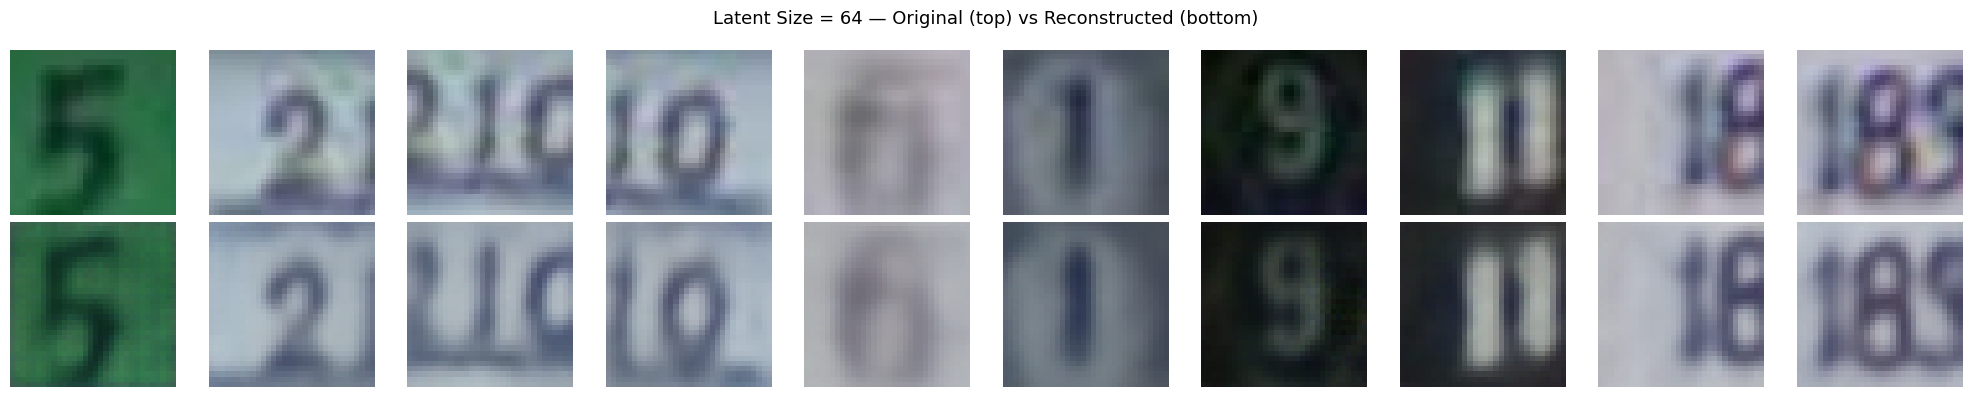

In [11]:
def show_reconstructions(model, images, n=10, title_prefix=''):
    """
    Display n original images and their reconstructions side by side.
    Top row: originals. Bottom row: reconstructions.
    """
    sample = images[:n]
    reconstructed = model.predict(sample, verbose=0)
    reconstructed = np.clip(reconstructed, 0, 1)

    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4))
    for i in range(n):
        # Original
        axes[0, i].imshow(sample[i])
        axes[0, i].axis('off')
        if i == 0:
            axes[0, i].set_ylabel('Original', fontsize=11, labelpad=5)
        # Reconstructed
        axes[1, i].imshow(reconstructed[i])
        axes[1, i].axis('off')
        if i == 0:
            axes[1, i].set_ylabel('Reconstructed', fontsize=11, labelpad=5)

    plt.suptitle(f'{title_prefix} — Original (top) vs Reconstructed (bottom)', fontsize=13)
    plt.tight_layout()
    plt.show()

show_reconstructions(autoencoder_64, X_test, n=10, title_prefix='Latent Size = 64')

## 6. Experiment 4.2 — Latent Representation Analysis



In [12]:
# Extract latent vectors for the first 1000 test images using the standalone encoder
latent_vectors_64 = encoder_64.predict(X_test[:1000], verbose=0)

print('='*55)
print('Latent Representation — Latent Size 64')
print('='*55)
print(f'Shape of latent vectors batch : {latent_vectors_64.shape}')   # (1000, 64)
print(f'Shape of a SINGLE latent vector: {latent_vectors_64[0].shape}')  # (64,)
print()
print('Example latent vector (first test image):')
print(np.round(latent_vectors_64[0], 4))

Latent Representation — Latent Size 64
Shape of latent vectors batch : (1000, 64)
Shape of a SINGLE latent vector: (64,)

Example latent vector (first test image):
[10.9414  8.9009 14.0776  8.8351 14.6724  9.9111 39.1415  2.9997  9.0355
 11.006   0.     17.9641  7.939   8.4542  6.8749 47.2103  0.     10.3111
  9.8507 53.4299  6.3532  3.6015 11.5936 10.5858 21.4182 16.9948 23.6847
  1.4877 20.2798 28.706  29.2869  7.2619 12.2846 17.1368 12.3535 13.3227
  0.1868 34.8686 11.7694 23.478   3.6387  2.7348  0.     14.6803 15.6569
  3.707   0.     16.2569 14.3354 50.0866 43.1617 33.6425  5.4937 11.3093
 15.1763  9.969  19.1262 24.9906 13.806   0.     25.1825  0.     20.237
 38.1905]


Mean   : 15.3061
Std    : 12.7512
Min    : 0.0000
Max    : 53.4299


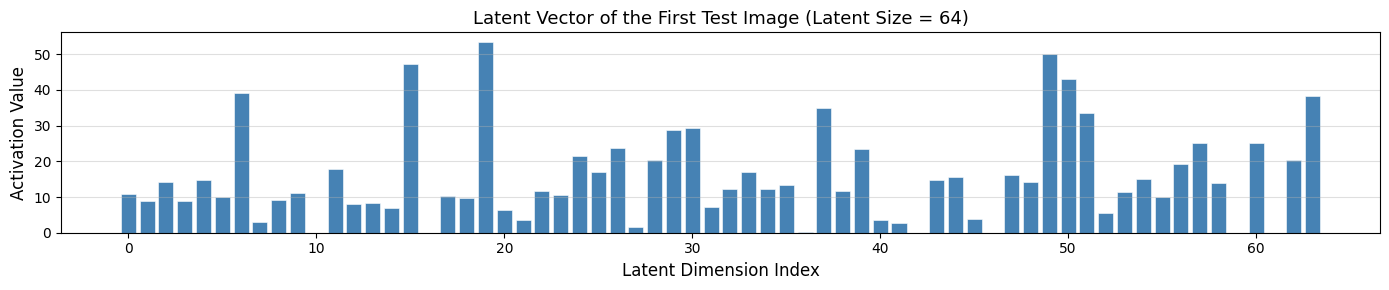

In [13]:
# Statistical summary of latent vectors
print(f'Mean   : {latent_vectors_64[0].mean():.4f}')
print(f'Std    : {latent_vectors_64[0].std():.4f}')
print(f'Min    : {latent_vectors_64[0].min():.4f}')
print(f'Max    : {latent_vectors_64[0].max():.4f}')

# Visualise the latent vector as a bar chart
plt.figure(figsize=(14, 3))
plt.bar(range(64), latent_vectors_64[0], color='steelblue', edgecolor='white', linewidth=0.4)
plt.xlabel('Latent Dimension Index', fontsize=12)
plt.ylabel('Activation Value', fontsize=12)
plt.title('Latent Vector of the First Test Image (Latent Size = 64)', fontsize=13)
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

## 7. Experiment 4.3 — Latent Size Comparison



In [14]:
# Build and compile autoencoder with latent_dim = 16
autoencoder_16, encoder_16, decoder_16 = build_autoencoder(latent_dim=16)

autoencoder_16.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse'
)

callbacks_16 = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1, min_lr=1e-6)
]

history_16 = autoencoder_16.fit(
    X_train, X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, X_test),
    callbacks=callbacks_16,
    verbose=1
)

Epoch 1/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 25s 58ms/step - loss: 0.0134 - val_loss: 0.0574 - learning_rate: 0.0010
Epoch 2/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0078 - val_loss: 0.0079 - learning_rate: 0.0010
Epoch 3/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0061 - val_loss: 0.0078 - learning_rate: 0.0010
Epoch 4/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - loss: 0.0058 - val_loss: 0.0103 - learning_rate: 0.0010
Epoch 5/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0055 - val_loss: 0.0067 - learning_rate: 0.0010
Epoch 6/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0054 - val_loss: 0.0061 - learning_rate: 0.0010
Epoch 7/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0053 - val_loss: 0.0060 - learning_rate: 0.0010
Epoch 8/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - loss: 0.0053 - val_loss: 0.0059 - learning_rate: 0.0010
Epoch 9/25
287/287 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0052 - val_loss: 0.0056 - learning_rate:

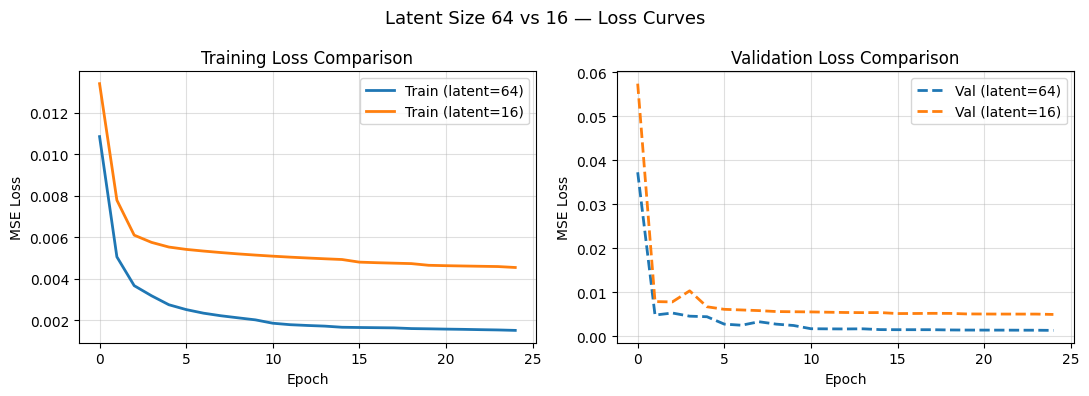

In [15]:
# Plot training curves for both latent sizes
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(history_64.history['loss'],     label='Train (latent=64)', linewidth=2)
plt.plot(history_16.history['loss'],     label='Train (latent=16)', linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('Training Loss Comparison')
plt.legend(); plt.grid(alpha=0.4)

plt.subplot(1, 2, 2)
plt.plot(history_64.history['val_loss'], label='Val (latent=64)', linewidth=2, linestyle='--')
plt.plot(history_16.history['val_loss'], label='Val (latent=16)', linewidth=2, linestyle='--')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('Validation Loss Comparison')
plt.legend(); plt.grid(alpha=0.4)

plt.suptitle('Latent Size 64 vs 16 — Loss Curves', fontsize=13)
plt.tight_layout()
plt.show()

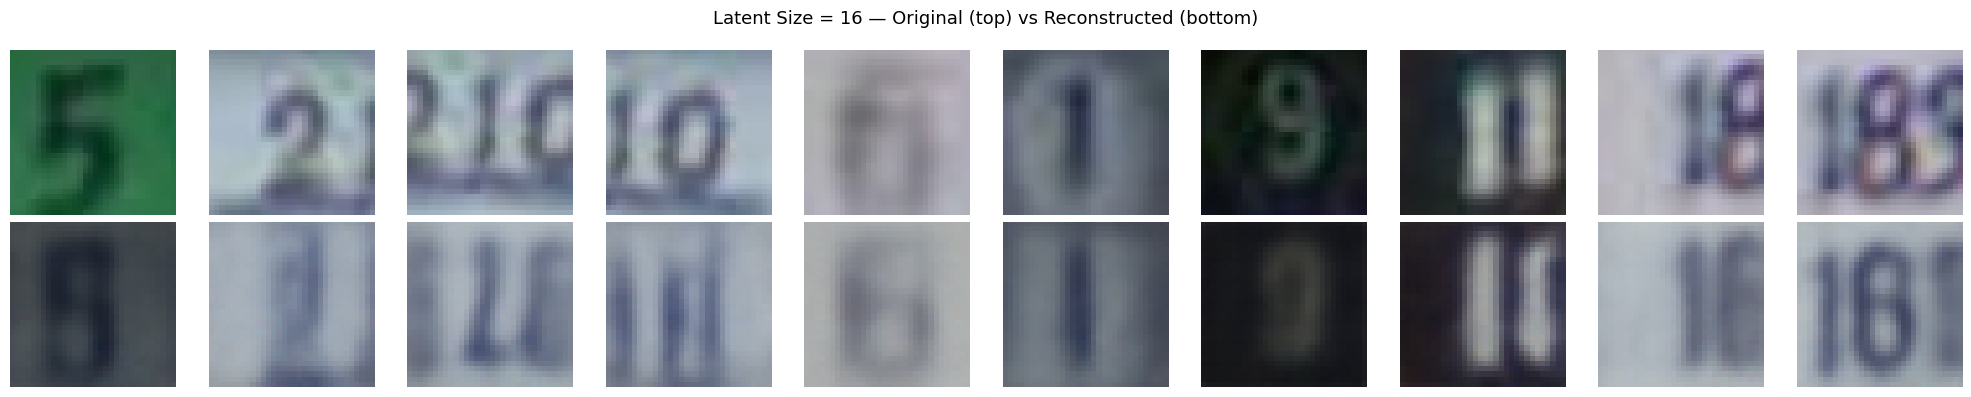

In [16]:
# Show reconstructions for latent size 16
show_reconstructions(autoencoder_16, X_test, n=10, title_prefix='Latent Size = 16')

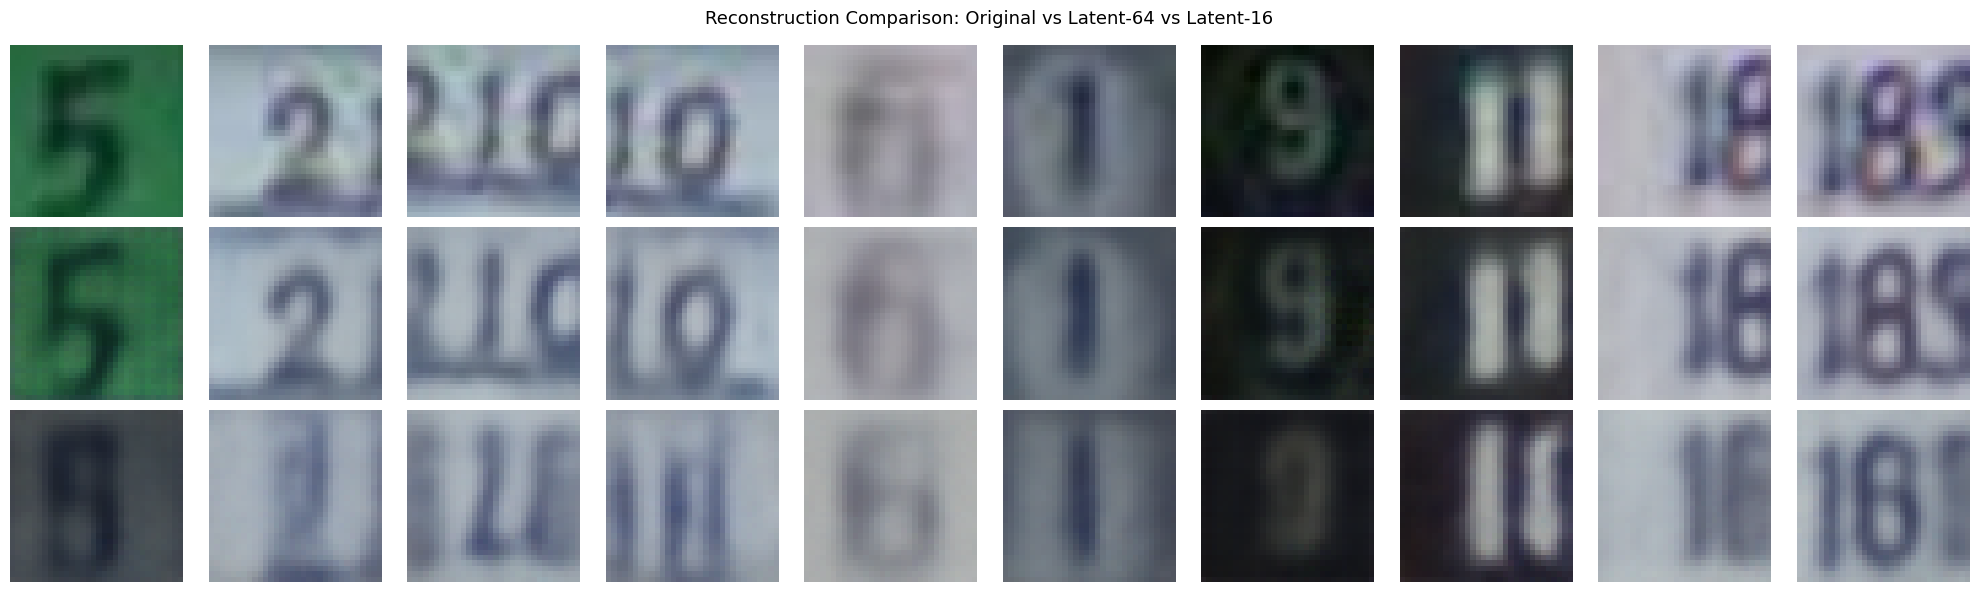

In [17]:
# ── Side-by-side comparison: Original | Latent-64 | Latent-16 ──
n = 10
sample = X_test[:n]
recon_64 = np.clip(autoencoder_64.predict(sample, verbose=0), 0, 1)
recon_16 = np.clip(autoencoder_16.predict(sample, verbose=0), 0, 1)

fig, axes = plt.subplots(3, n, figsize=(2 * n, 6))
row_labels = ['Original', 'Latent=64', 'Latent=16']
for col in range(n):
    axes[0, col].imshow(sample[col]);  axes[0, col].axis('off')
    axes[1, col].imshow(recon_64[col]); axes[1, col].axis('off')
    axes[2, col].imshow(recon_16[col]); axes[2, col].axis('off')

for row_idx, label in enumerate(row_labels):
    axes[row_idx, 0].set_ylabel(label, fontsize=11, labelpad=5)

plt.suptitle('Reconstruction Comparison: Original vs Latent-64 vs Latent-16', fontsize=13)
plt.tight_layout()
plt.show()

In [18]:
# Extract and compare latent vectors for both models
latent_vectors_16 = encoder_16.predict(X_test[:1000], verbose=0)

print('='*55)
print('LATENT SIZE = 64')
print('='*55)
print(f'Batch shape : {latent_vectors_64.shape}')      # (1000, 64)
print(f'Single vector shape: {latent_vectors_64[0].shape}')  # (64,)
print('Example latent vector:')
print(np.round(latent_vectors_64[0], 4))

print()
print('='*55)
print('LATENT SIZE = 16')
print('='*55)
print(f'Batch shape : {latent_vectors_16.shape}')      # (1000, 16)
print(f'Single vector shape: {latent_vectors_16[0].shape}')  # (16,)
print('Example latent vector:')
print(np.round(latent_vectors_16[0], 4))

LATENT SIZE = 64
Batch shape : (1000, 64)
Single vector shape: (64,)
Example latent vector:
[10.9414  8.9009 14.0776  8.8351 14.6724  9.9111 39.1415  2.9997  9.0355
 11.006   0.     17.9641  7.939   8.4542  6.8749 47.2103  0.     10.3111
  9.8507 53.4299  6.3532  3.6015 11.5936 10.5858 21.4182 16.9948 23.6847
  1.4877 20.2798 28.706  29.2869  7.2619 12.2846 17.1368 12.3535 13.3227
  0.1868 34.8686 11.7694 23.478   3.6387  2.7348  0.     14.6803 15.6569
  3.707   0.     16.2569 14.3354 50.0866 43.1617 33.6425  5.4937 11.3093
 15.1763  9.969  19.1262 24.9906 13.806   0.     25.1825  0.     20.237
 38.1905]

LATENT SIZE = 16
Batch shape : (1000, 16)
Single vector shape: (16,)
Example latent vector:
[20.4612 23.4099  8.9555 18.5569 17.4016 29.3599 27.044  23.1613 22.9817
 22.7941 36.8245 14.9504 18.3477 16.1601 10.4986 29.3552]


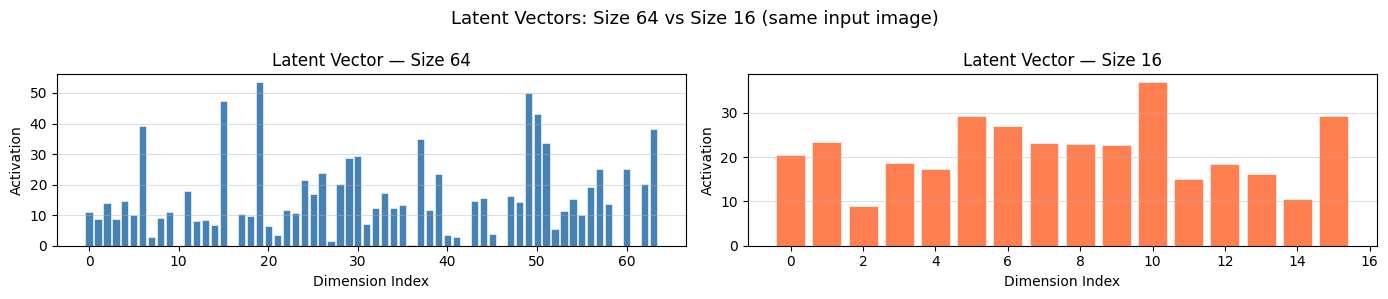

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

axes[0].bar(range(64), latent_vectors_64[0], color='steelblue', edgecolor='white', linewidth=0.4)
axes[0].set_title('Latent Vector — Size 64', fontsize=12)
axes[0].set_xlabel('Dimension Index'); axes[0].set_ylabel('Activation')
axes[0].grid(axis='y', alpha=0.4)

axes[1].bar(range(16), latent_vectors_16[0], color='coral', edgecolor='white', linewidth=0.4)
axes[1].set_title('Latent Vector — Size 16', fontsize=12)
axes[1].set_xlabel('Dimension Index'); axes[1].set_ylabel('Activation')
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('Latent Vectors: Size 64 vs Size 16 (same input image)', fontsize=13)
plt.tight_layout()
plt.show()

In [20]:
# Quantitative reconstruction quality comparison (MSE on test set)
mse_64 = autoencoder_64.evaluate(X_test, X_test, batch_size=256, verbose=0)
mse_16 = autoencoder_16.evaluate(X_test, X_test, batch_size=256, verbose=0)

print(f'Test MSE — Latent Size 64 : {mse_64:.6f}')
print(f'Test MSE — Latent Size 16 : {mse_16:.6f}')
print(f'\nLatent-16 MSE is {(mse_16/mse_64 - 1)*100:.1f}% higher than Latent-64.')

Test MSE — Latent Size 64 : 0.001361
Test MSE — Latent Size 16 : 0.004981

Latent-16 MSE is 265.9% higher than Latent-64.


## 8.  Effect of Latent Dimension Size



Demonstrating that latent-16 preserves sufficient information



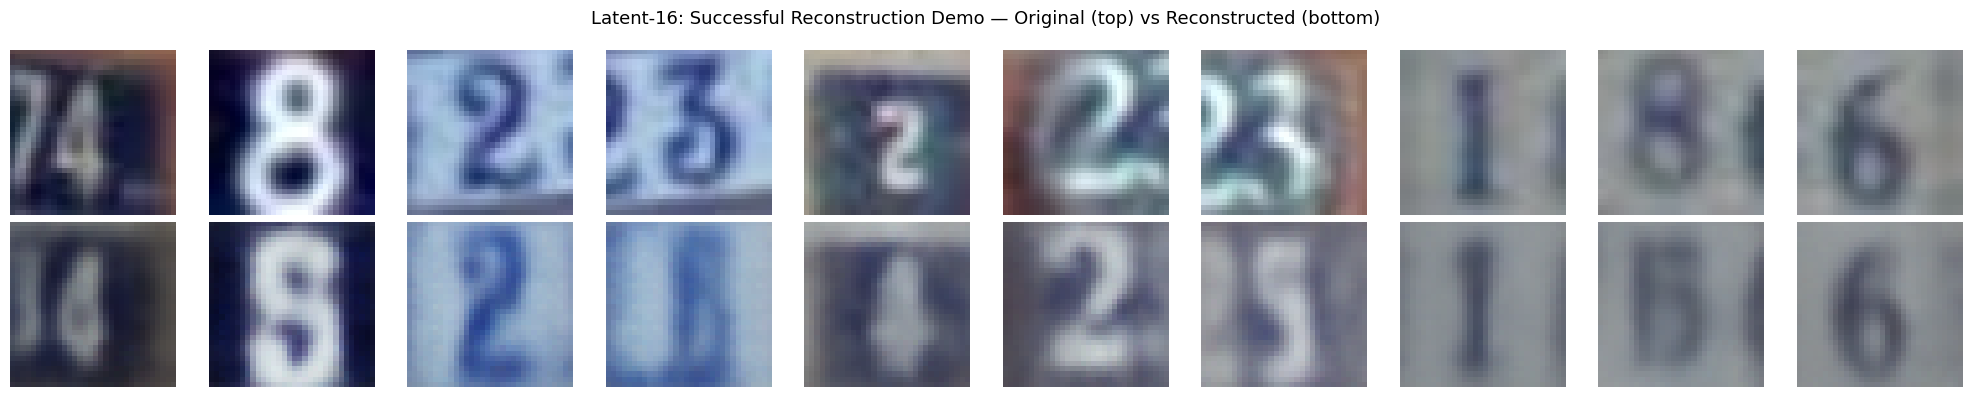

In [21]:
# Final demonstration: latent-16 still preserves sufficient information
print('Demonstrating that latent-16 preserves sufficient information\n')
show_reconstructions(autoencoder_16, X_test[100:110], n=10,
                     title_prefix='Latent-16: Successful Reconstruction Demo')